# Coumarin Generalizations ML work

This notebook contains all python scripts concerned with the Machine Learning work and models that will attempt generalization on a new coumarin.

The sections in this notebook are:
1. Feature Engineering
2. XGBoost Regressor
3. XGBoost classifier
4. More Regression models
5. More Classification models

---
## Feature Engineering

The descriptor features of the coumarins in the dataset will be defined here and will be added to
the dataset as new features.

Head of the data after new features:
╭────┬────────────────────┬──────────┬─────────────┬────────────┬────────┬────────┬─────────────┬──────────────┬──────────────┬──────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────┬────────┬──────────────┬─────────────────┬──────────────────┬────────┬──────────────┬─────────╮
│    │ Author             │ Cancer   │ Cell Line   │ Coumarin   │   Dose │   Time │   Viability │   Unnamed: 7 │   Unnamed: 8 │   Unnamed: 9 │   Unnamed: 10 │   Unnamed: 11 │   Unnamed: 12 │   Unnamed: 13 │   Unnamed: 14 │    MW │   LogP │   NumHDonors │   NumHAcceptors │   RotatableBonds │   TPSA │   RingCounts │   fCsp3 │
├────┼────────────────────┼──────────┼─────────────┼────────────┼────────┼────────┼─────────────┼──────────────┼──────────────┼──────────────┼───────────────┼───────────────┼───────────────┼───────────────┼───────────────┼───────┼────────┼──────────────┼─────────────────┼──────────────────┼────────┼───────────

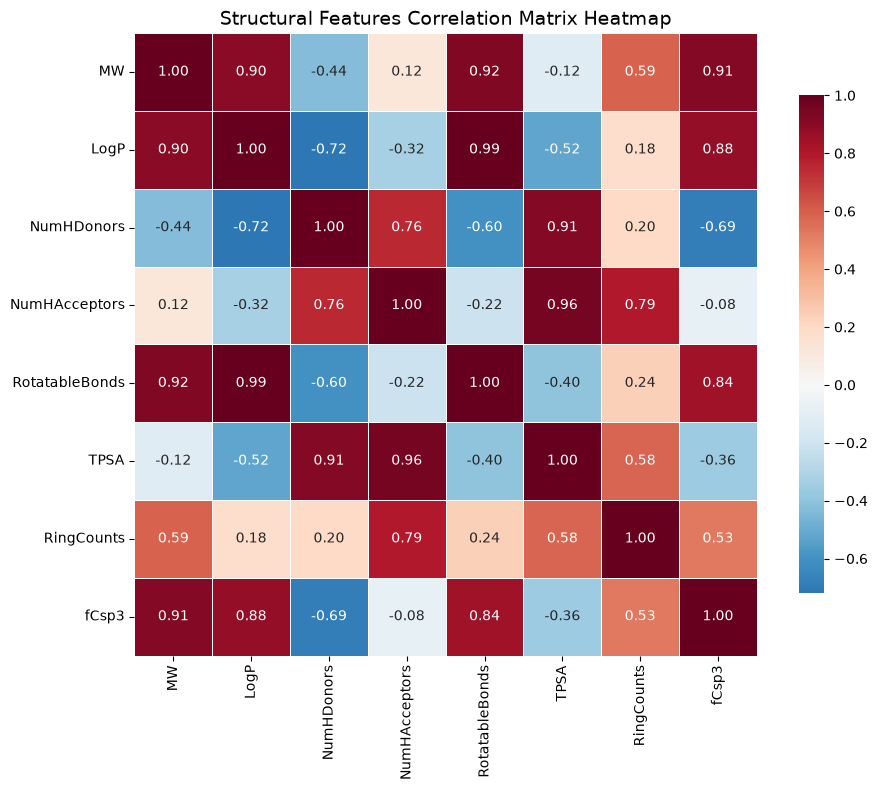

In [ ]:
import numpy as np
import pandas as pd
from tabulate import tabulate
import matplotlib.pylab as plt
import seaborn as sns

# All features Engineering will be done in this script, and kept separated from the general preProcessing

# The first obvious feature to add will be the Molecular Weights (From PubChem)
MWs = {"Auraptene": 298.4,
       "Osthole": 244.28,
       "Esculetin": 178.14,
       "GalbanicAcid": 398.5,
       "Umbelliprenin": 366.5};

# The second Important Feature will be LogP (XLogP3 From PubChem)
LogPs = {"Auraptene": 5.3,
         "Osthole": 3.8,
         "Esculetin": 1.2,
         "GalbanicAcid": 5.1,
         "Umbelliprenin": 7.1}

# Number of the Hydrogen bond donors
numHDonors = {"Auraptene": 0,
              "Osthole": 0,
              "Esculetin": 2,
              "GalbanicAcid": 1,
              "Umbelliprenin": 0}

# Number of the Hydrohen bond acceptors
numHAcceptors = {"Auraptene": 3,
                 "Osthole": 3,
                 "Esculetin": 4,
                 "GalbanicAcid": 5,
                 "Umbelliprenin": 3}

# Number of rotatable bonds
rotatableBonds = {"Auraptene": 6,
                  "Osthole": 3,
                  "Esculetin": 0,
                  "GalbanicAcid": 6,
                  "Umbelliprenin": 9}

# Topological Polar Surface Area (From PubChem)
TPSAs = {"Auraptene": 35.5,
         "Osthole": 35.5,
         "Esculetin": 66.8,
         "GalbanicAcid": 72.8,
         "Umbelliprenin": 35.5}

# Ring Counts
ringCounts = {"Auraptene": 2,
              "Osthole": 2,
              "Esculetin": 2,
              "GalbanicAcid": 3,
              "Umbelliprenin": 2}

# FractionCsp3: The fraction of carbon atoms that are sp3 hybridized.
fCsp3s = {"Auraptene": 0.32,
          "Osthole": 0.27,
          "Esculetin": 0,
          "GalbanicAcid": 0.5,
          "Umbelliprenin": 0.38}


# Read the data
data = pd.read_csv("Data/Data.csv")

# Remove null columns
data = data.dropna(axis=1)

# Remove whitspace from the coumarin values
data["Coumarin"] = data["Coumarin"].str.replace(r'\s+', '', regex=True)

# Add the new features
data["MW"] = data["Coumarin"].map(MWs)
data["LogP"] = data["Coumarin"].map(LogPs)
data["NumHDonors"] = data["Coumarin"].map(numHDonors)
data["NumHAcceptors"] = data["Coumarin"].map(numHAcceptors)
data["RotatableBonds"] = data["Coumarin"].map(rotatableBonds)
data["TPSA"] = data["Coumarin"].map(TPSAs)
data["RingCounts"] = data["Coumarin"].map(ringCounts)
data["fCsp3"] = data["Coumarin"].map(fCsp3s)

# Save the data
data.to_csv("Data/Engineered_Data.csv",index=False)                                 

# Take a look at the new data structure and columns
print("Head of the data after new features:")
print(tabulate(data.head(), headers='keys', tablefmt='rounded_grid'))

# Check out the correlation matrix of the new features (Ring counts excluded due to low variation)
cols = ["MW", "LogP", "NumHDonors", "NumHAcceptors", "RotatableBonds", "TPSA","RingCounts", "fCsp3"]

corr_matrix = data[cols].corr()
print("\nCorrelation Matrix of the newly engineered features:")
print(tabulate(corr_matrix, headers='keys', tablefmt='rounded_grid'))

# Create heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, 
            annot=True,                # Show values
            cmap='RdBu_r',             # Color scheme
            center=0,                  # Center colormap at 0
            fmt='.2f',                 # 2 decimal places
            square=True,               # Square cells
            linewidths=0.5,            # Grid lines
            cbar_kws={"shrink": 0.8})  # Colorbar size

plt.title('Engineered Features Correlation Matrix Heatmap', fontsize=14)
plt.tight_layout()

# Given the results of the Correlation matrix I have decided that adding cross features could be
# of negative effect to the overall generalization process.

---
## XGBoostRegressor



In [ ]:
import numpy as np
np.random.seed(42)  # All random processes are seeded with 42 for reproducibility

import pandas as pd
import os
import json
import joblib

from xgboost import XGBRegressor

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    train_test_split,
    KFold,
    GroupKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

from tabulate import tabulate

# Load the data
data = pd.read_csv("Data/Engineered_Data.csv")

# Set constants here
RANDOM_STATE = 42
RESULTS_DIR = "Results/Regression/XGboost/"
MODELS_DIR = RESULTS_DIR + "Models/"
EVALUATIONS_DIR = RESULTS_DIR + "Evaluations/"
PARAMETERS_DIR = RESULTS_DIR + "BestParameters/"
N_ITER = 3000 # Number of iterations for the random search

# Make the required directories if they do not exist
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(EVALUATIONS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(PARAMETERS_DIR, exist_ok=True)

print("=" * 70)
print("STARTING XGBOOST REGRESSION SCRIPT")
print("=" * 70)

print()
print("Head of the raw data: (Shuffled to see more variance in the data)\n")
print(tabulate(data.sample(frac=1).head(), headers='keys', tablefmt="rounded_grid"))
print()

# Set X and y
print()
print("=" * 70)
print("DEFINING X AND y")
print("=" * 70)
print()
X = data.drop(columns=["Viability", "Author", "Coumarin"], inplace=False)
y = data['Viability']

print("X features:")
print(tabulate(pd.DataFrame(X.columns), tablefmt="rounded_grid"), end="\n\n")
print("The y vector has been set to the `Viability` feature")

# Define the categorical and numerical features
categorical_features = ["Cancer", "CellLine"]
numerical_features = X.columns.drop(["Cancer", "CellLine"]).tolist()

# Define Groups for evaluation and parameter searching
data["GroupID"] = (
    data["Author"].astype(str) + "_" +
    data["Coumarin"].astype(str) + "_" +
    data["CellLine"].astype(str) + "_" +
    data["Time"].astype(str)
)
print()
print("=" * 70)
print("Defining Grouping Strategies")
print("=" * 70)
print()

print("1. Grouping using the Author, Coumarin, CellLinem and Time Features")
print("Number of uniquely identified groups:", data["GroupID"].nunique())
print()

print("2. Grouping using the Coumarin feature")
print("Number Groups using only Coumarins:", data["Coumarin"].nunique())
print()

print("3. The final strategy will be the usual Kfold using 5 folds")

# Prepare the preprocessor
preprocessor = ColumnTransformer(
    transformers= [(
        "cat",
        OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
        categorical_features
    ),
    (
        "num",
        "passthrough",
        numerical_features
    )]
)

# Initialize the base model object
model = XGBRegressor(
    objective="reg:squarederror",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

# Define pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

# Define the search grid of the model for fine tuning the hyper parameters (Using randomSearch)
param_distributions = {
    "model__n_estimators": [
        100, 150, 200, 300, 400, 500,
        600, 800, 1000
    ],

    "model__max_depth": [
        2, 3, 4, 5, 6, 7, 8
    ],

    "model__learning_rate": [
        0.005, 0.01, 0.02, 0.03,
        0.05, 0.075, 0.1, 0.15, 0.2
    ],

    "model__subsample": [
        0.5, 0.6, 0.7, 0.8,
        0.9, 1.0
    ],

    "model__colsample_bytree": [
        0.5, 0.6, 0.7, 0.8,
        0.9, 1.0
    ],

    "model__min_child_weight": [
        1, 2, 3, 5, 7, 10
    ],

    "model__gamma": [
        0, 0.01, 0.05, 0.1,
        0.2, 0.5, 1.0
    ],

    "model__reg_alpha": [
        0, 0.001, 0.01, 0.1, 1.0
    ],

    "model__reg_lambda": [
        0.1, 0.5, 1, 2, 5, 10
    ]
}

# Evaluation methods:
eval_methods = {
    "Kfold" : {
        "splitter" : KFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE
        ),
        "groups" : None
    },

    "GroupID" : {
        "splitter" : GroupKFold(
            n_splits=5
        ),
        "groups" : data["GroupID"]
    },

    "Coumarin" : {
        "splitter" : GroupKFold(
            n_splits=data["Coumarin"].nunique()
        ),
        "groups" : data["Coumarin"]
    }
}

# Next up we'll define some helpers so that reproducubility under different conditions is simplified

#===================================================================================================
# Helper function to get the results of evaluation
def calculate_metrics(y_true, y_pred):
    """
    Returns a Dict containing the following metrics as keys:
    - "MAE"
    - "RMSE"
    - "MedAE"
    - "R2"

    :param y_true: The true y vector.
    :param y_pred: The y that has been predicted by a model.
    """
    return {
        "MAE" : mean_absolute_error(y_true, y_pred),
        "RMSE" : np.sqrt(mean_squared_error(y_true, y_pred)),
        "MedAE" : median_absolute_error(y_true, y_pred),
        "R2" : r2_score(y_true, y_pred)
    };

# A helper function to return a new pipeline if needed
def create_model():

    return Pipeline([
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    (
                        "cat",
                        OneHotEncoder(
                            sparse_output=False,
                            handle_unknown="ignore"
                        ),
                        categorical_features
                    ),
                    (
                        "num",
                        "passthrough",
                        numerical_features
                    )
                ]
            )
        ),
        (
            "model",
            XGBRegressor(
                objective="reg:squarederror",
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        )
    ]);

# Helper function that will return a pipeline that has been fitted to the given params
def create_model_with_params(best_params):

    model_pipeline = create_model()

    model_pipeline.set_params(
        **best_params
    )

    return model_pipeline;

# A Function that will allow us to perform the search under different conditions if needed
def search_best_parameters(method_name, splitter, groups):
    """
    Performs RandomizedSearchCV if the best-parameter JSON
    does not already exist.

    If the JSON exists, the search is skipped and the
    previously determined parameters are loaded instead.
    """

    parameter_path = (
        PARAMETERS_DIR +
        f"XGBoost_{method_name}.json"
    )

    print()
    print("=" * 70)
    print(f"Starting hyperparameter search: {method_name}")
    print("=" * 70)
    print()

    # --------------------------------------------------------
    # Check whether the search has already been performed
    # --------------------------------------------------------

    if os.path.exists(parameter_path):

        print(f"[{method_name}] Best parameters already exist.")
        print("Skipping hyperparameter search.")

        with open(
            parameter_path,
            "r"
        ) as file:

            best_params = json.load(file)

        return best_params


    # --------------------------------------------------------
    # Perform the search if the json does not exist
    # --------------------------------------------------------

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=N_ITER,
        scoring="r2",
        cv=splitter,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=False,
        verbose=1
    )

    if groups is None:

        search.fit(
            X,
            y
        )

    else:

        search.fit(
            X,
            y,
            groups=groups
        )

    # --------------------------------------------------------
    # Retrieve best parameters post searching
    # --------------------------------------------------------

    best_params = search.best_params_

    print()
    print(
        f"Best CV R2 for {method_name}: "
        f"{search.best_score_:.6f}"
    )

    print()
    print("Best parameters:")

    for parameter, value in best_params.items():
        print(
            f"  {parameter}: {value}"
        )

    # --------------------------------------------------------
    # Save parameters
    # --------------------------------------------------------

    with open(
        parameter_path,
        "w"
    ) as file:

        json.dump(
            best_params,
            file,
            indent=4
        )

    print()
    print(
        f"Best parameters saved to: "
        f"{parameter_path}"
    )

    return best_params;

# A function that will allow us to find metrics other than the R2 used in the search
def evaluate_model(
    method_name,
    splitter,
    groups,
    best_params
):
    """
    Evaluates a model with fixed hyperparameters using the
    same CV strategy that was used during hyperparameter
    searching.

    A fresh model is fitted for every fold.

    Returns:
        - fold-level results
        - mean metrics
        - standard deviations
    """

    print()
    print("=" * 70)
    print(
        f"Evaluating best model: using {method_name} splitting method"
    )
    print("=" * 70)
    print()

    fold_results = []

    # --------------------------------------------------------
    # Generate the same CV splits used during the search
    # --------------------------------------------------------

    if groups is None:

        split_iterator = splitter.split(
            X,
            y
        )

    else:

        split_iterator = splitter.split(
            X,
            y,
            groups=groups
        )

    # --------------------------------------------------------
    # Evaluate every fold
    # --------------------------------------------------------

    for fold_number, (train_idx, test_idx) in enumerate(
        split_iterator,
        start=1
    ):

        print(
            f"Evaluating fold {fold_number}..."
        )

        # Find the left out coumarin in case that we are doing the coumarin method.
        left_out_coumarin = None
        if method_name == "Coumarin" :
            left_out_coumarin = str(data.iloc[test_idx]["Coumarin"].iloc[0])
            print("Left Out Coumarin is:", left_out_coumarin)

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        # Fresh model for this fold
        fold_model = create_model_with_params(
            best_params
        )

        # Fit ONLY on the training portion
        fold_model.fit(
            X_train,
            y_train
        )

        # Predict the held-out portion
        y_pred = fold_model.predict(
            X_test
        )

        # Calculate all metrics
        metrics = calculate_metrics(
            y_test,
            y_pred
        )

        fold_results.append({
            "Method": method_name,
            "Fold": fold_number,
            "Left Out Coumarin" : left_out_coumarin,
            **metrics
        })

        print(
            f"  R2:    {metrics['R2']:.6f}"
        )
        print(
            f"  MAE:   {metrics['MAE']:.6f}"
        )
        print(
            f"  RMSE:  {metrics['RMSE']:.6f}"
        )
        print(
            f"  MedAE: {metrics['MedAE']:.6f}"
        )
        print()

    # --------------------------------------------------------
    # Convert fold results to DataFrame
    # --------------------------------------------------------

    fold_results_df = pd.DataFrame(
        fold_results
    )

    # --------------------------------------------------------
    # Calculate mean and standard deviation
    # --------------------------------------------------------

    metrics = [
        "MAE",
        "RMSE",
        "MedAE",
        "R2"
    ]

    summary = {}

    for metric in metrics:

        summary[
            f"{metric}_Mean"
        ] = fold_results_df[metric].mean()

        summary[
            f"{metric}_Std"
        ] = fold_results_df[metric].std()

    return fold_results_df, summary;
#===================================================================================================

# We are done with the helper functions now we can start the process of searching and evaluating

all_fold_results = []
all_summary_results = []

for method_name, method in eval_methods.items():
    
    # Set the splitter and the groups to be used in the search and evaluation
    splitter = method["splitter"]
    groups = method["groups"]

    # Get the best_params from the model
    best_params = search_best_parameters(
        method_name=method_name,
        splitter=splitter,
        groups=groups
    )

    # Get the results of the evaluation
    fold_results_df, summary = evaluate_model(
        method_name=method_name,
        splitter=splitter,
        groups=groups,
        best_params=best_params
    )

    # Store fold level results
    all_fold_results.append(fold_results_df)

    # Store our summary
    all_summary_results.append({
        "Method" : method_name,
        **summary # unpack the summary dict
    });


# Lets combine the results to one df
all_fold_results_df = pd.concat(all_fold_results, ignore_index=True)
summary_df = pd.DataFrame(all_summary_results)

# Log the results in the terminal
print()
print("=" * 70)
print("FOLD-LEVEL EVALUATION RESULTS")
print("=" * 70)
print()

print(tabulate(all_fold_results_df, headers="keys", tablefmt="rounded_grid", showindex=False, floatfmt=".6f"))

print()
print("=" * 70)
print("EVALUATION SUMMARY")
print("=" * 70)
print()

print(tabulate(summary_df, headers="keys", tablefmt="rounded_grid", showindex=False, floatfmt=".6f"))

# Now we can finally save the results as a csv file
all_fold_results_df.to_csv(
    EVALUATIONS_DIR +
    "XGBoost_FoldResults.csv",
    index=False
)

summary_df.to_csv(
    EVALUATIONS_DIR +
    "XGBoost_EvaluationSummary.csv",
    index=False
)

print()
print("Evaluation results saved.")

# Now that we are done with searching and evaluating, We can finally train the models on the whole dataset
print()
print("=" * 70)
print("TRAINING FINAL MODELS")
print("=" * 70)
print()


for method_name, method in eval_methods.items():

    parameter_path = (
        PARAMETERS_DIR +
        f"XGBoost_{method_name}.json"
    )

    model_path = (
        MODELS_DIR +
        f"XGBoost_{method_name}.joblib"
    )

    # --------------------------------------------------------
    # Load best parameters
    # --------------------------------------------------------

    with open(
        parameter_path,
        "r"
    ) as file:

        best_params = json.load(file)

    # --------------------------------------------------------
    # Create fresh model
    # --------------------------------------------------------

    final_model = create_model_with_params(
        best_params
    )

    # --------------------------------------------------------
    # Train on ALL available data
    # --------------------------------------------------------

    final_model.fit(
        X,
        y
    )

    # --------------------------------------------------------
    # Save final model
    # --------------------------------------------------------

    joblib.dump(
        final_model,
        model_path
    )

    print(f"{method_name} final model saved to:")
    print(f"  {model_path}")

print()
print("=" * 70)
print("PREFERED SCOPOLETIN AND IMPERATORIN SAMPLES")
print("=" * 70)
print()

print("In order to find the prefered samples, we wanted to see which CellLine and Timepoint combinations appear among most Coumarins.")

cellline_time_summary = (
    data.groupby(["CellLine", "Time"])["Coumarin"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="NumberOfCoumarins")
)

# Consider combinations that appear among at least 4 coumarins:
cellline_time_summary = cellline_time_summary[cellline_time_summary["NumberOfCoumarins"] >= 3]

print("\nCellLine + Time combinations ranked by number of Coumarins:")
print(tabulate(cellline_time_summary, headers='keys', tablefmt='rounded_grid'))

# We can now move onto validating and testing our model on new coumarins and samples not in the dataset
print()
print("=" * 70)
print("Loading Validation Samples")
print("=" * 70)
print()
# Load the Validation samples:
validation_samples = pd.read_csv("Data/FarnesiferolC&Umbelliprenin.csv")
print("Farnesiferol C and Umbelliprenin sample count:", validation_samples.__len__())

# Transform the new validation samples to a dataframe containing

print()
print("=" * 70)
print("TESTING THE MODEL ON FARNESIFEROL_C SAMPLES")
print("=" * 70)
print()

farenesiferolC_samples = [{
    "Cancer" : [],
    "CellLine" : [],
    "Dose" : [],
    "Time" : [],
    "Viability" : []
    },
]

farenesiferolC_structural_features = {
    "MW" : 382.5, # From PubChem
    "LogP" : 5.5, # From PubChem
    "NumHDonors" : 0, # From PubChem
    "NumHAcceptors" : 4, # From PubChem
    "RotatableBonds" : 6, # From PubChem
    "TPSA" : 44.8, # From PubChem
    "RingCounts" : 2, # From PubChem Figure
    "fCsp3" : 0.54 # From SwissADME
}


print()
print("=" * 70)
print("TESTING THE MODEL ON SCOPOLETIN SAMPLES")
print("=" * 70)
print()

scopoletin_samples = [{
    "Cancer" : [],
    "CellLine" : [],
    "Dose" : [],
    "Time" : [],
    "Viability" : []
    },
]

scopoletin_structural_features = {
    "MW" : 192.17, # From PubChem
    "LogP" : 1.5, # From PubChem
    "NumHDonors" : 1, # From PubChem
    "NumHAcceptors" : 4, # From PubChem
    "RotatableBonds" : 1, # From PubChem
    "TPSA" : 55.8, # From PubChem
    "RingCounts" : 2, # From PubChem Figure
    "fCsp3" : 0.10 # From SwissADME
}

print()
print("=" * 70)
print("TESTING THE MODEL ON IMPERATORIN SAMPLES")
print("=" * 70)
print()

imperatorin_samples = [{
    "Cancer" : [],
    "CellLine" : [],
    "Dose" : [],
    "Time" : [],
    "Viability" : []
    },
]

imperatorin_structural_features = {
    "MW" : 270.28, # From PubChem
    "LogP" : 3.4, # From PubChem
    "NumHDonors" : 0, # From PubChem
    "NumHAcceptors" : 4, # From PubChem
    "RotatableBonds" : 3, # From PubChem
    "TPSA" : 48.7, # From PubChem
    "RingCounts" : 3, # From PubChem Figure
    "fCsp3" : 0.19 # From SwissADME
}


print()
print("=" * 70)
print("FINISHED SCRIPT SUCCESSFULLY!!!")
print("=" * 70)
print()

STARTING XGBOOST REGRESSION SCRIPT

Head of the raw data: (Shuffled to see more variance in the data)

╭──────┬───────────────────┬───────────────────┬────────────┬───────────────┬────────┬────────┬─────────────┬────────┬────────┬──────────────┬─────────────────┬──────────────────┬────────┬──────────────┬─────────╮
│      │ Author            │ Cancer            │ CellLine   │ Coumarin      │   Dose │   Time │   Viability │     MW │   LogP │   NumHDonors │   NumHAcceptors │   RotatableBonds │   TPSA │   RingCounts │   fCsp3 │
├──────┼───────────────────┼───────────────────┼────────────┼───────────────┼────────┼────────┼─────────────┼────────┼────────┼──────────────┼─────────────────┼──────────────────┼────────┼──────────────┼─────────┤
│  618 │ Goudarzi et al.   │ leukemia:lymphoma │ MT-2       │ Galbanic Acid │     10 │     72 │       92.2  │ nan    │  nan   │          nan │             nan │              nan │  nan   │          nan │  nan    │
├──────┼───────────────────┼─────────────

## XGBoost Classification
In the following script we use the xgboost classification model and the viability feature has been transformed to two classes under the following condition:
> if |Viability - 50| ≤ 5 then set Viability to 1, set Viability to 0 otherwise

Afterwards all the same steps in the xgboost regression script are taken.

In [ ]:
import numpy as np
np.random.seed(42)  # All random processes are seeded with 42 for reproducibility

import pandas as pd
import os
import json
import joblib

from xgboost import XGBClassifier

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    KFold,
    GroupKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

from tabulate import tabulate

# Load the data
data = pd.read_csv("Data/Engineered_Data.csv")

print("=" * 70)
print("STARTING XGBOOST CLASSIFICATION SCRIPT")
print("=" * 70)

# Make the Viability feature categorical(1 if |Viability - 50| ≤ 5 and 0 otherwise)
print()
print("=" * 70)
print("TRANSFORMING VIABILITY FEATURE FOR CLASSIFICATION")
print("=" * 70)
print()

data["Target"] = (
    (data["Viability"] - 50).abs() <= 5
).astype(int)

print("Target has been transformed using the following criteria:")
print("if |Viability - 50| <= 5 then Target = 1, otherwise Target = 0")

# The distribution of the classes
print("The distribution of the new clasees of Viability:")
print(tabulate(pd.DataFrame(data["Target"].value_counts()), headers="keys", tablefmt="rounded_grid"))

# Set constants here
RANDOM_STATE = 42
RESULTS_DIR = "Results/Classification/XGboost"
MODELS_DIR = RESULTS_DIR + "Models/"
EVALUATIONS_DIR = RESULTS_DIR + "Evaluations/"
PARAMETERS_DIR = RESULTS_DIR + "BestParameters/"
N_ITER = 3000 # Number of iterations for the random search

# Make the required directories if they do not exist
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(EVALUATIONS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(PARAMETERS_DIR, exist_ok=True)

# Take a look at the head of the data
print()
print("Head of the raw data: (Shuffled to see more variance in the data)\n")
print(tabulate(data.sample(frac=1).head(), headers='keys', tablefmt="rounded_grid"))
print()

# Set X and y
print()
print("=" * 70)
print("DEFINING X AND y")
print("=" * 70)
print()
X = data.drop(columns=["Target", "Viability", "Author", "Coumarin"], inplace=False)
y = data['Target']

print("X features:")
print(tabulate(pd.DataFrame(X.columns), tablefmt="rounded_grid"), end="\n\n")
print("The y vector has been set to the new `Target` feature (Viability transformed to be 2 classes)")

# Define the categorical and numerical features
categorical_features = ["Cancer", "CellLine"]
numerical_features = X.columns.drop(["Cancer", "CellLine"]).tolist()

# Define Groups for evaluation and parameter searching
data["GroupID"] = (
    data["Author"].astype(str) + "_" +
    data["Coumarin"].astype(str) + "_" +
    data["CellLine"].astype(str) + "_" +
    data["Time"].astype(str)
)
print()
print("=" * 70)
print("Defining Grouping Strategies")
print("=" * 70)
print()

print("1. Grouping using the Author, Coumarin, CellLinem and Time Features")
print("Number of uniquely identified groups:", data["GroupID"].nunique())
print()

print("2. Grouping using the Coumarin feature")
print("Number Groups using only Coumarins:", data["Coumarin"].nunique())
print()

print("3. The final strategy will be the usual Kfold using 5 folds")

# Prepare the preprocessor
preprocessor = ColumnTransformer(
    transformers= [(
        "cat",
        OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
        categorical_features
    ),
    (
        "num",
        "passthrough",
        numerical_features
    )]
)

# Initialize the base model object
model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

# Define pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

# Define the search grid of the model for fine tuning the hyper parameters (Using randomSearch)
param_distributions = {

    # Number of boosting rounds
    "model__n_estimators": [
        100, 150, 200, 300, 400, 500,
        600, 800, 1000
    ],

    # Maximum depth of each tree
    "model__max_depth": [
        2, 3, 4, 5, 6, 7, 8
    ],

    # Step size for each boosting round
    "model__learning_rate": [
        0.005, 0.01, 0.02, 0.03,
        0.05, 0.075, 0.1, 0.15, 0.2
    ],

    # Fraction of samples used for each tree
    "model__subsample": [
        0.5, 0.6, 0.7, 0.8,
        0.9, 1.0
    ],

    # Fraction of features used for each tree
    "model__colsample_bytree": [
        0.5, 0.6, 0.7, 0.8,
        0.9, 1.0
    ],

    # Minimum sum of instance weights needed in a child
    "model__min_child_weight": [
        1, 2, 3, 5, 7, 10
    ],

    # Minimum loss reduction required for another split
    "model__gamma": [
        0, 0.01, 0.05, 0.1,
        0.2, 0.5, 1.0
    ],

    # L1 regularization
    "model__reg_alpha": [
        0, 0.001, 0.01, 0.1, 1.0
    ],

    # L2 regularization
    "model__reg_lambda": [
        0.1, 0.5, 1, 2, 5, 10
    ],

    # Since the classes are imbalanced
    "model__scale_pos_weight": [
    1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15
    ]
}

# Evaluation methods:
eval_methods = {
    "Kfold" : {
        "splitter" : KFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE
        ),
        "groups" : None
    },

    "GroupID" : {
        "splitter" : GroupKFold(
            n_splits=5
        ),
        "groups" : data["GroupID"]
    },

    "Coumarin" : {
        "splitter" : GroupKFold(
            n_splits=data["Coumarin"].nunique()
        ),
        "groups" : data["Coumarin"]
    }
}

# Next up we'll define some helpers so that reproducubility under different conditions is simplified

#===================================================================================================
# Helper function to get the results of evaluation
def calculate_metrics(y_true, y_pred, y_prob):

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),

        "BalancedAccuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "ROC_AUC": np.nan,
        "PR_AUC": average_precision_score(
            y_true,
            y_prob
        )
    }

    # ROC-AUC requires both classes to be present
    if len(np.unique(y_true)) == 2:
        metrics["ROC_AUC"] = roc_auc_score(
            y_true,
            y_prob
        )

    return metrics

# A helper function to return a new pipeline if needed
def create_model():

    return Pipeline([
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    (
                        "cat",
                        OneHotEncoder(
                            sparse_output=False,
                            handle_unknown="ignore"
                        ),
                        categorical_features
                    ),
                    (
                        "num",
                        "passthrough",
                        numerical_features
                    )
                ]
            )
        ),
        (
            "model",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        )
    ])

# Helper function that will return a pipeline that has been fitted to the given params
def create_model_with_params(best_params):

    model_pipeline = create_model()

    model_pipeline.set_params(
        **best_params
    )

    return model_pipeline;

# A Function that will allow us to perform the search under different conditions if needed
def search_best_parameters(method_name, splitter, groups):
    """
    Performs RandomizedSearchCV if the best-parameter JSON
    does not already exist.

    If the JSON exists, the search is skipped and the
    previously determined parameters are loaded instead.
    """

    parameter_path = (
        PARAMETERS_DIR +
        f"XGBoost_{method_name}.json"
    )

    print()
    print("=" * 70)
    print(f"Starting hyperparameter search: {method_name}")
    print("=" * 70)
    print()

    # --------------------------------------------------------
    # Check whether the search has already been performed
    # --------------------------------------------------------

    if os.path.exists(parameter_path):

        print(f"[{method_name}] Best parameters already exist.")
        print("Skipping hyperparameter search.")

        with open(
            parameter_path,
            "r"
        ) as file:

            best_params = json.load(file)

        return best_params


    # --------------------------------------------------------
    # Perform the search if the json does not exist
    # --------------------------------------------------------

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=N_ITER,
        scoring="roc_auc",
        cv=splitter,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=False,
        verbose=1
    )

    if groups is None:

        search.fit(
            X,
            y
        )

    else:

        search.fit(
            X,
            y,
            groups=groups
        )

    # --------------------------------------------------------
    # Retrieve best parameters post searching
    # --------------------------------------------------------

    best_params = search.best_params_

    print()
    print(
        f"Best CV ROC-AUC for {method_name}: "
        f"{search.best_score_:.6f}"
    )

    print()
    print("Best parameters:")

    for parameter, value in best_params.items():
        print(
            f"  {parameter}: {value}"
        )

    # --------------------------------------------------------
    # Save parameters
    # --------------------------------------------------------

    with open(
        parameter_path,
        "w"
    ) as file:

        json.dump(
            best_params,
            file,
            indent=4
        )

    print()
    print(
        f"Best parameters saved to: "
        f"{parameter_path}"
    )

    return best_params;

# A function that will allow us to find metrics other than the ROC-AUC used in the search
def evaluate_model(
    method_name,
    splitter,
    groups,
    best_params
):
    """
    Evaluates a model with fixed hyperparameters using the
    same CV strategy that was used during hyperparameter
    searching.

    A fresh model is fitted for every fold.

    Returns:
        - fold-level results
        - mean metrics
        - standard deviations
    """

    print()
    print("=" * 70)
    print(
        f"Evaluating best model: using {method_name} splitting method"
    )
    print("=" * 70)
    print()

    fold_results = []

    # --------------------------------------------------------
    # Generate the same CV splits used during the search
    # --------------------------------------------------------

    if groups is None:

        split_iterator = splitter.split(
            X,
            y
        )

    else:

        split_iterator = splitter.split(
            X,
            y,
            groups=groups
        )

    # --------------------------------------------------------
    # Evaluate every fold
    # --------------------------------------------------------

    for fold_number, (train_idx, test_idx) in enumerate(
        split_iterator,
        start=1
    ):

        print(
            f"Evaluating fold {fold_number}..."
        )

        # Find the left out coumarin in case that we are doing the coumarin method.
        left_out_coumarin = None
        if method_name == "Coumarin" :
            left_out_coumarin = str(data.iloc[test_idx]["Coumarin"].iloc[0])
            print("Left Out Coumarin is:", left_out_coumarin)

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        # Fresh model for this fold
        fold_model = create_model_with_params(
            best_params
        )

        # Fit ONLY on the training portion
        fold_model.fit(
            X_train,
            y_train
        )

        # Predict the held-out portion
        y_pred = fold_model.predict(X_test)
        y_prob = fold_model.predict_proba(X_test)[:, 1]

        print("  Actual class distribution:")
        print(pd.Series(y_test).value_counts().to_dict())

        print("  Predicted class distribution:")
        print(pd.Series(y_pred).value_counts().to_dict())

        print(
            f"  Predicted probability range: "
            f"{y_prob.min():.4f} - {y_prob.max():.4f}"
        )

        print(
            f"  Mean predicted probability: "
            f"{y_prob.mean():.4f}"
        )

        # Calculate all metrics
        metrics = calculate_metrics(
            y_test,
            y_pred,
            y_prob
        )

        fold_results.append({
            "Method": method_name,
            "Fold": fold_number,
            "Left Out Coumarin" : left_out_coumarin,
            **metrics
        })

        print(
            f"  Accuracy:          {metrics['Accuracy']:.6f}"
        )
        print(
            f"  Balanced Accuracy: {metrics['BalancedAccuracy']:.6f}"
        )
        print(
            f"  Precision:         {metrics['Precision']:.6f}"
        )
        print(
            f"  Recall:            {metrics['Recall']:.6f}"
        )
        print(
            f"  F1:                {metrics['F1']:.6f}"
        )
        print(
            f"  ROC-AUC:           {metrics['ROC_AUC']:.6f}"
        )
        print(
            f"  PR-AUC:            {metrics['PR_AUC']:.6f}"
        )
        print()

    # --------------------------------------------------------
    # Convert fold results to DataFrame
    # --------------------------------------------------------

    fold_results_df = pd.DataFrame(
        fold_results
    )

    # --------------------------------------------------------
    # Calculate mean and standard deviation
    # --------------------------------------------------------

    metrics = [
        "Accuracy",
        "BalancedAccuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "PR_AUC"
    ]

    summary = {}

    for metric in metrics:

        summary[
            f"{metric}_Mean"
        ] = fold_results_df[metric].mean()

        summary[
            f"{metric}_Std"
        ] = fold_results_df[metric].std()

    return fold_results_df, summary
#===================================================================================================

# We are done with the helper functions now we can start the process of searching and evaluating

all_fold_results = []
all_summary_results = []

for method_name, method in eval_methods.items():
    
    # Set the splitter and the groups to be used in the search and evaluation
    splitter = method["splitter"]
    groups = method["groups"]

    # Get the best_params from the model
    best_params = search_best_parameters(
        method_name=method_name,
        splitter=splitter,
        groups=groups
    )

    # Get the results of the evaluation
    fold_results_df, summary = evaluate_model(
        method_name=method_name,
        splitter=splitter,
        groups=groups,
        best_params=best_params
    )

    # Store fold level results
    all_fold_results.append(fold_results_df)

    # Store our summary
    all_summary_results.append({
        "Method" : method_name,
        **summary # unpack the summary dict
    });


# Lets combine the results to one df
all_fold_results_df = pd.concat(all_fold_results, ignore_index=True)
summary_df = pd.DataFrame(all_summary_results)

# Log the results in the terminal
print()
print("=" * 70)
print("FOLD-LEVEL EVALUATION RESULTS")
print("=" * 70)
print()

print(tabulate(all_fold_results_df, headers="keys", tablefmt="rounded_grid", showindex=False, floatfmt=".6f"))

print()
print("=" * 70)
print("EVALUATION SUMMARY")
print("=" * 70)
print()

print(tabulate(summary_df, headers="keys", tablefmt="rounded_grid", showindex=False, floatfmt=".6f"))

# Now we can finally save the results as a csv file
all_fold_results_df.to_csv(
    EVALUATIONS_DIR +
    "XGBoost_FoldResults.csv",
    index=False
)

summary_df.to_csv(
    EVALUATIONS_DIR +
    "XGBoost_EvaluationSummary.csv",
    index=False
)

print()
print("Evaluation results saved.")

# Now that we are done with searching and evaluating, We can finally train the models on the whole dataset
print()
print("=" * 70)
print("TRAINING FINAL MODELS")
print("=" * 70)
print()


for method_name, method in eval_methods.items():

    parameter_path = (
        PARAMETERS_DIR +
        f"XGBoost_{method_name}.json"
    )

    model_path = (
        MODELS_DIR +
        f"XGBoost_{method_name}.joblib"
    )

    # --------------------------------------------------------
    # Load best parameters
    # --------------------------------------------------------

    with open(
        parameter_path,
        "r"
    ) as file:

        best_params = json.load(file)

    # --------------------------------------------------------
    # Create fresh model
    # --------------------------------------------------------

    final_model = create_model_with_params(
        best_params
    )

    # --------------------------------------------------------
    # Train on ALL available data
    # --------------------------------------------------------

    final_model.fit(
        X,
        y
    )

    # --------------------------------------------------------
    # Save final model
    # --------------------------------------------------------

    joblib.dump(
        final_model,
        model_path
    )

    print(f"{method_name} final model saved to:")
    print(f"  {model_path}")

print()
print("=" * 70)
print("PREFERED SCOPOLETIN AND IMPERATORIN SAMPLES")
print("=" * 70)
print()

print("In order to find the prefered samples, we wanted to see which CellLine and Timepoint combinations appear among most Coumarins.")

cellline_time_summary = (
    data.groupby(["CellLine", "Time"])["Coumarin"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="NumberOfCoumarins")
)

# Consider combinations that appear among at least 4 coumarins:
cellline_time_summary = cellline_time_summary[cellline_time_summary["NumberOfCoumarins"] >= 3]

print("\nCellLine + Time combinations ranked by number of Coumarins:")
print(tabulate(cellline_time_summary, headers='keys', tablefmt='rounded_grid'))

print()
print("=" * 70)
print("TESTING THE MODEL ON SCOPOLETIN SAMPLES")
print("=" * 70)
print()

scopoletin_samples = [{
    "Cancer" : [],
    "CellLine" : [],
    "Dose" : [],
    "Time" : [],
    "Viability" : []
    },
]

scopoletin_structural_features = {
    "MW" : 192.17, # From PubChem
    "LogP" : 1.5, # From PubChem
    "NumHDonors" : 1, # From PubChem
    "NumHAcceptors" : 4, # From PubChem
    "RotatableBonds" : 1, # From PubChem
    "TPSA" : 55.8, # From PubChem
    "RingCounts" : 2, # From PubChem Figure
    "fCsp3" : 0.10 # From SwissADME
}

print()
print("=" * 70)
print("TESTING THE MODEL ON IMPERATORIN SAMPLES")
print("=" * 70)
print()

imperatorin_samples = [{
    "Cancer" : [],
    "CellLine" : [],
    "Dose" : [],
    "Time" : [],
    "Viability" : []
    },
]

imperatorin_structural_features = {
    "MW" : 270.28, # From PubChem
    "LogP" : 3.4, # From PubChem
    "NumHDonors" : 0, # From PubChem
    "NumHAcceptors" : 4, # From PubChem
    "RotatableBonds" : 3, # From PubChem
    "TPSA" : 48.7, # From PubChem
    "RingCounts" : 3, # From PubChem Figure
    "fCsp3" : 0.19 # From SwissADME
}


print()
print("=" * 70)
print("FINISHED SCRIPT SUCCESSFULLY!!!")
print("=" * 70)
print()

STARTING XGBOOST CLASSIFICATION SCRIPT

TRANSFORMING VIABILITY FEATURE FOR CLASSIFICATION

Target has been transformed using the following criteria:
if |Viability - 50| <= 5 then Target = 1, otherwise Target = 0
The distribution of the new clasees of Viability:
╭──────────┬─────────╮
│   Target │   count │
├──────────┼─────────┤
│        0 │    1531 │
├──────────┼─────────┤
│        1 │     166 │
╰──────────┴─────────╯

Head of the raw data: (Shuffled to see more variance in the data)

╭──────┬───────────────────┬───────────────────┬────────────┬───────────────┬────────┬────────┬─────────────┬────────┬────────┬──────────────┬─────────────────┬──────────────────┬────────┬──────────────┬─────────┬──────────╮
│      │ Author            │ Cancer            │ CellLine   │ Coumarin      │   Dose │   Time │   Viability │     MW │   LogP │   NumHDonors │   NumHAcceptors │   RotatableBonds │   TPSA │   RingCounts │   fCsp3 │   Target │
├──────┼───────────────────┼───────────────────┼───────────

___
## More Regression Models

In this section we test out a variety of other regression models to see how they perform on the data and whether or not they can successfully generalize to new coumarins

In [ ]:
import numpy as np

np.random.seed(42)

import pandas as pd
import os
import json
import joblib

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    KFold,
    GroupKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.linear_model import (
    Ridge,
    ElasticNet
)

from sklearn.svm import SVR

from scipy.stats import loguniform

from tabulate import tabulate

import warnings

warnings.filterwarnings("ignore")


# ==================================================================================================
# CONSTANTS
# ==================================================================================================

RANDOM_STATE = 42

N_ITER = 300

DATA_PATH = "Data/Engineered_Data.csv"

RESULTS_DIR = "Results/Regression/OtherModels/"

MODELS_DIR = RESULTS_DIR + "Models/"
EVALUATIONS_DIR = RESULTS_DIR + "Evaluations/"
PARAMETERS_DIR = RESULTS_DIR + "BestParameters/"


# ==================================================================================================
# CREATE DIRECTORIES
# ==================================================================================================

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(EVALUATIONS_DIR, exist_ok=True)
os.makedirs(PARAMETERS_DIR, exist_ok=True)


# ==================================================================================================
# LOAD DATA
# ==================================================================================================

data = pd.read_csv(DATA_PATH)


print("=" * 70)
print("STARTING MULTI-MODEL REGRESSION SCRIPT")
print("=" * 70)
print()

print("Head of the raw data:\n")

print(
    tabulate(
        data.sample(frac=1).head(),
        headers="keys",
        tablefmt="rounded_grid"
    )
)

print()


# ==================================================================================================
# DEFINE X AND y
# ==================================================================================================

print("=" * 70)
print("DEFINING X AND y")
print("=" * 70)
print()


X = data.drop(
    columns=[
        "Viability",
        "Author",
        "Coumarin"
    ],
    inplace=False
)

y = data["Viability"]


print("X features:")

print(
    tabulate(
        pd.DataFrame(X.columns),
        tablefmt="rounded_grid"
    )
)

print()

print("The y vector has been set to the `Viability` feature.")


# ==================================================================================================
# FEATURE TYPES
# ==================================================================================================

categorical_features = [
    "Cancer",
    "CellLine"
]

numerical_features = X.columns.drop(
    categorical_features
).tolist()


# ==================================================================================================
# DEFINE GROUPS
# ==================================================================================================

data["GroupID"] = (
    data["Author"].astype(str)
    + "_"
    + data["Coumarin"].astype(str)
    + "_"
    + data["CellLine"].astype(str)
    + "_"
    + data["Time"].astype(str)
)


print()

print("=" * 70)
print("DEFINING GROUPING STRATEGIES")
print("=" * 70)
print()

print(
    "1. Grouping using Author, Coumarin, CellLine and Time"
)

print(
    "Number of uniquely identified groups:",
    data["GroupID"].nunique()
)

print()

print(
    "2. Grouping using Coumarin"
)

print(
    "Number of Coumarin groups:",
    data["Coumarin"].nunique()
)

print()

print(
    "3. Standard 5-fold KFold"
)


# ==================================================================================================
# EVALUATION METHODS
# ==================================================================================================

eval_methods = {

    "Kfold": {

        "splitter": KFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE
        ),

        "groups": None
    },

    "GroupID": {

        "splitter": GroupKFold(
            n_splits=5
        ),

        "groups": data["GroupID"]
    },

    "Coumarin": {

        "splitter": GroupKFold(
            n_splits=data["Coumarin"].nunique()
        ),

        "groups": data["Coumarin"]
    }
}


# ==================================================================================================
# PREPROCESSORS
# ==================================================================================================

def create_tree_preprocessor():

    return ColumnTransformer(

        transformers=[

            (
                "cat",

                OneHotEncoder(
                    sparse_output=False,
                    handle_unknown="ignore"
                ),

                categorical_features
            ),

            (
                "num",
                "passthrough",
                numerical_features
            )
        ]
    )


def create_scaled_preprocessor():

    return ColumnTransformer(

        transformers=[

            (
                "cat",

                OneHotEncoder(
                    sparse_output=False,
                    handle_unknown="ignore"
                ),

                categorical_features
            ),

            (
                "num",

                StandardScaler(),

                numerical_features
            )
        ]
    )


# ==================================================================================================
# MODEL DEFINITIONS
# ==================================================================================================

models = {

    "RandomForest": {

        "model": RandomForestRegressor(
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

        "preprocessor": create_tree_preprocessor(),

        "params": {

            "model__n_estimators": [
                100,
                200,
                300,
                500,
                800,
                1000
            ],

            "model__max_depth": [
                None,
                3,
                5,
                7,
                10,
                15,
                20,
                30
            ],

            "model__min_samples_split": [
                2,
                5,
                10,
                15,
                20
            ],

            "model__min_samples_leaf": [
                1,
                2,
                4,
                8,
                12
            ],

            "model__max_features": [
                0.5,
                0.7,
                1.0
            ]
        }
    },


    "ExtraTrees": {

        "model": ExtraTreesRegressor(
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

        "preprocessor": create_tree_preprocessor(),

        "params": {

            "model__n_estimators": [
                100,
                200,
                300,
                500,
                800,
                1000
            ],

            "model__max_depth": [
                None,
                3,
                5,
                7,
                10,
                15,
                20,
                30
            ],

            "model__min_samples_split": [
                2,
                5,
                10,
                15,
                20
            ],

            "model__min_samples_leaf": [
                1,
                2,
                4,
                8,
                12
            ],

            "model__max_features": [
                0.5,
                0.7,
                1.0
            ]
        }
    },


    "GradientBoosting": {

        "model": GradientBoostingRegressor(
            random_state=RANDOM_STATE
        ),

        "preprocessor": create_tree_preprocessor(),

        "params": {

            "model__n_estimators": [
                100,
                150,
                200,
                300,
                500,
                800
            ],

            "model__max_depth": [
                2,
                3,
                4,
                5,
                6,
                8
            ],

            "model__learning_rate": [
                0.005,
                0.01,
                0.02,
                0.03,
                0.05,
                0.075,
                0.1,
                0.15,
                0.2
            ],

            "model__subsample": [
                0.5,
                0.7,
                0.8,
                0.9,
                1.0
            ],

            "model__min_samples_split": [
                2,
                5,
                10,
                15,
                20
            ],

            "model__min_samples_leaf": [
                1,
                2,
                4,
                8,
                12
            ],

            "model__max_features": [
                None,
                "sqrt",
                "log2"
            ]
        }
    },


    "HistGradientBoosting": {

        "model": HistGradientBoostingRegressor(
            random_state=RANDOM_STATE
        ),

        "preprocessor": create_tree_preprocessor(),

        "params": {

            "model__max_iter": [
                100,
                150,
                200,
                300,
                500,
                800
            ],

            "model__learning_rate": [
                0.005,
                0.01,
                0.02,
                0.03,
                0.05,
                0.075,
                0.1,
                0.15,
                0.2
            ],

            "model__max_leaf_nodes": [
                7,
                15,
                31,
                63,
                127
            ],

            "model__max_depth": [
                None,
                3,
                5,
                7,
                10
            ],

            "model__min_samples_leaf": [
                5,
                10,
                15,
                20,
                30
            ],

            "model__l2_regularization": [
                0,
                0.01,
                0.1,
                1,
                10
            ]
        }
    },


    "Ridge": {

        "model": Ridge(),

        "preprocessor": create_scaled_preprocessor(),

        "params": {

            "model__alpha": [
                0.001,
                0.01,
                0.1,
                1,
                10,
                100,
                1000
            ]
        }
    },


    "ElasticNet": {

        "model": ElasticNet(
            max_iter=10000,
            random_state=RANDOM_STATE
        ),

        "preprocessor": create_scaled_preprocessor(),

        "params": {

            "model__alpha": [
                0.0001,
                0.001,
                0.01,
                0.1,
                1,
                10,
                100
            ],

            "model__l1_ratio": [
                0.0,
                0.1,
                0.25,
                0.5,
                0.75,
                0.9,
                1.0
            ]
        }
    },


    "SVR": {

        "model": SVR(),

        "preprocessor": create_scaled_preprocessor(),

        "params": {

            "model__C": loguniform(
                0.01,
                1000
            ),

            "model__gamma": [
                "scale",
                "auto"
            ],

            "model__epsilon": [
                0.01,
                0.05,
                0.1,
                0.2,
                0.3,
                0.5,
                1.0
            ],

            "model__kernel": [
                "rbf"
            ]
        }
    }
}


# ==================================================================================================
# HELPER: CREATE MODEL
# ==================================================================================================

def create_model(model_name):

    model_info = models[model_name]

    return Pipeline([

        (
            "preprocessor",
            model_info["preprocessor"]
        ),

        (
            "model",
            model_info["model"]
        )
    ])


# ==================================================================================================
# HELPER: CREATE MODEL WITH PARAMETERS
# ==================================================================================================

def create_model_with_params(
    model_name,
    best_params
):

    model_pipeline = create_model(
        model_name
    )

    model_pipeline.set_params(
        **best_params
    )

    return model_pipeline


# ==================================================================================================
# METRICS
# ==================================================================================================

def calculate_metrics(
    y_true,
    y_pred
):

    return {

        "MAE":
            mean_absolute_error(
                y_true,
                y_pred
            ),

        "RMSE":
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            ),

        "MedAE":
            median_absolute_error(
                y_true,
                y_pred
            ),

        "R2":
            r2_score(
                y_true,
                y_pred
            )
    }


# ==================================================================================================
# HYPERPARAMETER SEARCH
# ==================================================================================================

def search_best_parameters(
    model_name,
    method_name,
    splitter,
    groups
):

    parameter_path = (

        PARAMETERS_DIR
        + f"{model_name}_{method_name}.json"
    )


    print()
    print("=" * 70)

    print(
        f"Starting hyperparameter search:"
        f" {model_name} - {method_name}"
    )

    print("=" * 70)
    print()


    # ------------------------------------------------
    # Check existing parameters
    # ------------------------------------------------

    if os.path.exists(parameter_path):

        print(
            f"[{model_name} - {method_name}] "
            "Best parameters already exist."
        )

        print(
            "Skipping hyperparameter search."
        )

        with open(
            parameter_path,
            "r"
        ) as file:

            best_params = json.load(file)

        return best_params


    # ------------------------------------------------
    # Create pipeline
    # ------------------------------------------------

    pipeline = create_model(
        model_name
    )


    # ------------------------------------------------
    # Create search
    # ------------------------------------------------

    search = RandomizedSearchCV(

        estimator=pipeline,

        param_distributions=models[
            model_name
        ]["params"],

        n_iter=N_ITER,

        scoring="r2",

        cv=splitter,

        random_state=RANDOM_STATE,

        n_jobs=-1,

        refit=False,

        verbose=1
    )


    # ------------------------------------------------
    # Fit search
    # ------------------------------------------------

    if groups is None:

        search.fit(
            X,
            y
        )

    else:

        search.fit(
            X,
            y,
            groups=groups
        )


    # ------------------------------------------------
    # Get best parameters
    # ------------------------------------------------

    best_params = search.best_params_


    print()

    print(
        f"Best CV R2 for "
        f"{model_name} - {method_name}: "
        f"{search.best_score_:.6f}"
    )

    print()

    print("Best parameters:")

    for parameter, value in best_params.items():

        print(
            f"  {parameter}: {value}"
        )


    # ------------------------------------------------
    # Save parameters
    # ------------------------------------------------

    with open(
        parameter_path,
        "w"
    ) as file:

        json.dump(
            best_params,
            file,
            indent=4
        )


    print()

    print(
        "Best parameters saved to:"
    )

    print(
        f"  {parameter_path}"
    )


    return best_params


# ==================================================================================================
# MODEL EVALUATION
# ==================================================================================================

def evaluate_model(
    model_name,
    method_name,
    splitter,
    groups,
    best_params
):

    print()

    print("=" * 70)

    print(
        f"Evaluating {model_name}: "
        f"using {method_name} splitting method"
    )

    print("=" * 70)

    print()


    fold_results = []


    # ------------------------------------------------
    # Generate CV splits
    # ------------------------------------------------

    if groups is None:

        split_iterator = splitter.split(
            X,
            y
        )

    else:

        split_iterator = splitter.split(
            X,
            y,
            groups=groups
        )


    # ------------------------------------------------
    # Evaluate folds
    # ------------------------------------------------

    for fold_number, (
        train_idx,
        test_idx
    ) in enumerate(
        split_iterator,
        start=1
    ):

        print(
            f"Evaluating fold {fold_number}..."
        )


        # ------------------------------------------------
        # Identify left-out coumarin
        # ------------------------------------------------

        left_out_coumarin = None


        if method_name == "Coumarin":

            left_out_coumarin = str(
                data.iloc[test_idx]["Coumarin"].iloc[0]
            )

            print(
                "Left Out Coumarin:",
                left_out_coumarin
            )


        # ------------------------------------------------
        # Split data
        # ------------------------------------------------

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]


        # ------------------------------------------------
        # Fresh model
        # ------------------------------------------------

        fold_model = create_model_with_params(

            model_name,

            best_params
        )


        # ------------------------------------------------
        # Train
        # ------------------------------------------------

        fold_model.fit(
            X_train,
            y_train
        )


        # ------------------------------------------------
        # Predict
        # ------------------------------------------------

        y_pred = fold_model.predict(
            X_test
        )


        # ------------------------------------------------
        # Calculate metrics
        # ------------------------------------------------

        metrics = calculate_metrics(
            y_test,
            y_pred
        )


        fold_results.append({

            "Model":
                model_name,

            "Method":
                method_name,

            "Fold":
                fold_number,

            "Left Out Coumarin":
                left_out_coumarin,

            **metrics
        })


        print(
            f"  R2:    {metrics['R2']:.6f}"
        )

        print(
            f"  MAE:   {metrics['MAE']:.6f}"
        )

        print(
            f"  RMSE:  {metrics['RMSE']:.6f}"
        )

        print(
            f"  MedAE: {metrics['MedAE']:.6f}"
        )

        print()


    # ------------------------------------------------
    # DataFrame
    # ------------------------------------------------

    fold_results_df = pd.DataFrame(
        fold_results
    )


    # ------------------------------------------------
    # Calculate summary
    # ------------------------------------------------

    metric_names = [
        "MAE",
        "RMSE",
        "MedAE",
        "R2"
    ]


    summary = {}


    for metric in metric_names:

        summary[
            f"{metric}_Mean"
        ] = fold_results_df[
            metric
        ].mean()


        summary[
            f"{metric}_Std"
        ] = fold_results_df[
            metric
        ].std()


    return (
        fold_results_df,
        summary
    )


# ==================================================================================================
# MAIN TRAINING / EVALUATION LOOP
# ==================================================================================================

all_fold_results = []

all_summary_results = []


for model_name in models:

    print()

    print("#" * 70)

    print(
        f"PROCESSING MODEL: {model_name}"
    )

    print("#" * 70)


    for method_name, method in eval_methods.items():

        splitter = method["splitter"]

        groups = method["groups"]


        # ------------------------------------------------
        # Hyperparameter search
        # ------------------------------------------------

        best_params = search_best_parameters(

            model_name=model_name,

            method_name=method_name,

            splitter=splitter,

            groups=groups
        )


        # ------------------------------------------------
        # Evaluation
        # ------------------------------------------------

        fold_results_df, summary = evaluate_model(

            model_name=model_name,

            method_name=method_name,

            splitter=splitter,

            groups=groups,

            best_params=best_params
        )


        # ------------------------------------------------
        # Store results
        # ------------------------------------------------

        all_fold_results.append(
            fold_results_df
        )


        all_summary_results.append({

            "Model":
                model_name,

            "Method":
                method_name,

            **summary
        })


# ==================================================================================================
# COMBINE RESULTS
# ==================================================================================================

all_fold_results_df = pd.concat(
    all_fold_results,
    ignore_index=True
)


summary_df = pd.DataFrame(
    all_summary_results
)


# ==================================================================================================
# PRINT FOLD RESULTS
# ==================================================================================================

print()

print("=" * 70)

print(
    "FOLD-LEVEL EVALUATION RESULTS"
)

print("=" * 70)

print()


print(
    tabulate(
        all_fold_results_df,
        headers="keys",
        tablefmt="rounded_grid",
        showindex=False,
        floatfmt=".6f"
    )
)


# ==================================================================================================
# PRINT SUMMARY
# ==================================================================================================

print()

print("=" * 70)

print(
    "EVALUATION SUMMARY"
)

print("=" * 70)

print()


print(
    tabulate(
        summary_df,
        headers="keys",
        tablefmt="rounded_grid",
        showindex=False,
        floatfmt=".6f"
    )
)


# ==================================================================================================
# SAVE EVALUATIONS
# ==================================================================================================

all_fold_results_df.to_csv(

    EVALUATIONS_DIR
    + "AllModels_FoldResults.csv",

    index=False
)


summary_df.to_csv(

    EVALUATIONS_DIR
    + "AllModels_EvaluationSummary.csv",

    index=False
)


# ==================================================================================================
# TRAIN FINAL MODELS
# ==================================================================================================

print()

print("=" * 70)

print(
    "TRAINING FINAL MODELS"
)

print("=" * 70)

print()


for model_name in models:

    for method_name in eval_methods:

        parameter_path = (

            PARAMETERS_DIR
            + f"{model_name}_{method_name}.json"
        )


        model_path = (

            MODELS_DIR
            + f"{model_name}_{method_name}.joblib"
        )


        # ------------------------------------------------
        # Load best parameters
        # ------------------------------------------------

        with open(
            parameter_path,
            "r"
        ) as file:

            best_params = json.load(
                file
            )


        # ------------------------------------------------
        # Create model
        # ------------------------------------------------

        final_model = create_model_with_params(

            model_name,

            best_params
        )


        # ------------------------------------------------
        # Train on all data
        # ------------------------------------------------

        final_model.fit(
            X,
            y
        )


        # ------------------------------------------------
        # Save model
        # ------------------------------------------------

        joblib.dump(
            final_model,
            model_path
        )


        print(
            f"{model_name} - {method_name} "
            "final model saved to:"
        )

        print(
            f"  {model_path}"
        )


print()

print("=" * 70)

print(
    "ALL MODELS FINISHED SUCCESSFULLY!"
)

print("=" * 70)

print()

___
## More Classification Models

In this section we test out a variety of other classification models to see how they perform on the data and whether or not they can successfully generalize to new coumarins

In [1]:
import numpy as np

np.random.seed(42)

import pandas as pd
import os
import json
import joblib

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    KFold,
    GroupKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.svm import SVC

from tabulate import tabulate


# ===================================================================================================
# LOAD DATA
# ===================================================================================================

data = pd.read_csv(
    "Data/Engineered_Data.csv"
)

print("=" * 70)
print("STARTING MULTI-MODEL CLASSIFICATION SCRIPT")
print("=" * 70)


# ===================================================================================================
# TRANSFORM VIABILITY INTO CLASSIFICATION TARGET
# ===================================================================================================

print()
print("=" * 70)
print("TRANSFORMING VIABILITY FEATURE FOR CLASSIFICATION")
print("=" * 70)
print()

data["Target"] = (
    (data["Viability"] - 50).abs() <= 5
).astype(int)

print(
    "Target has been transformed using the following criteria:"
)

print(
    "if |Viability - 50| <= 5 then Target = 1, otherwise Target = 0"
)

print()

print("Distribution of the new classes:")

print(
    tabulate(
        pd.DataFrame(
            data["Target"].value_counts()
        ),
        headers="keys",
        tablefmt="rounded_grid"
    )
)


# ===================================================================================================
# CONSTANTS
# ===================================================================================================

RANDOM_STATE = 42

RESULTS_DIR = "Results/Classification/OtherModels/"

MODELS_DIR = RESULTS_DIR + "Models/"
EVALUATIONS_DIR = RESULTS_DIR + "Evaluations/"
PARAMETERS_DIR = RESULTS_DIR + "BestParameters/"

N_ITER = 50


# ===================================================================================================
# CREATE DIRECTORIES
# ===================================================================================================

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

os.makedirs(
    EVALUATIONS_DIR,
    exist_ok=True
)

os.makedirs(
    MODELS_DIR,
    exist_ok=True
)

os.makedirs(
    PARAMETERS_DIR,
    exist_ok=True
)


# ===================================================================================================
# DISPLAY DATA
# ===================================================================================================

print()

print(
    "Head of the raw data:"
)

print()

print(
    tabulate(
        data.sample(frac=1).head(),
        headers="keys",
        tablefmt="rounded_grid"
    )
)


# ===================================================================================================
# DEFINE X AND y
# ===================================================================================================

print()
print("=" * 70)
print("DEFINING X AND y")
print("=" * 70)
print()

X = data.drop(
    columns=[
        "Target",
        "Viability",
        "Author",
        "Coumarin"
    ],
    inplace=False
)

y = data["Target"]

print("X features:")

print(
    tabulate(
        pd.DataFrame(X.columns),
        tablefmt="rounded_grid"
    )
)

print()

print(
    "The y vector has been set to the Target feature."
)


# ===================================================================================================
# FEATURE TYPES
# ===================================================================================================

categorical_features = [
    "Cancer",
    "CellLine"
]

numerical_features = X.columns.drop(
    categorical_features
).tolist()


# ===================================================================================================
# DEFINE GROUPS
# ===================================================================================================

data["GroupID"] = (
    data["Author"].astype(str) + "_" +
    data["Coumarin"].astype(str) + "_" +
    data["CellLine"].astype(str) + "_" +
    data["Time"].astype(str)
)

print()
print("=" * 70)
print("DEFINING GROUPING STRATEGIES")
print("=" * 70)
print()

print(
    "1. Grouping using Author, Coumarin, CellLine and Time"
)

print(
    "Number of unique groups:",
    data["GroupID"].nunique()
)

print()

print(
    "2. Grouping using Coumarin"
)

print(
    "Number of Coumarin groups:",
    data["Coumarin"].nunique()
)

print()

print(
    "3. Standard KFold using 5 folds"
)


# ===================================================================================================
# EVALUATION METHODS
# ===================================================================================================

eval_methods = {

    "Kfold": {

        "splitter": KFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE
        ),

        "groups": None
    },

    "GroupID": {

        "splitter": GroupKFold(
            n_splits=5
        ),

        "groups": data["GroupID"]
    },

    "Coumarin": {

        "splitter": GroupKFold(
            n_splits=data["Coumarin"].nunique()
        ),

        "groups": data["Coumarin"]
    }
}


# ===================================================================================================
# MODEL DEFINITIONS
# ===================================================================================================

models = {

    "LogisticRegression": {

        "model": LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ),

        "scale": True,

        "params": {

            "model__C": [
                0.001,
                0.01,
                0.1,
                0.5,
                1,
                2,
                5,
                10,
                50,
                100
            ],

            "model__solver": [
                "lbfgs",
                "liblinear"
            ],

            "model__class_weight": [
                None,
                "balanced"
            ]
        }
    },


    "RandomForest": {

        "model": RandomForestClassifier(
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

        "scale": False,

        "params": {

            "model__n_estimators": [
                100,
                200,
                300,
                500,
                800,
                1000
            ],

            "model__max_depth": [
                None,
                3,
                5,
                8,
                10,
                15,
                20,
                30
            ],

            "model__min_samples_split": [
                2,
                5,
                10,
                20
            ],

            "model__min_samples_leaf": [
                1,
                2,
                5,
                10
            ],

            "model__max_features": [
                "sqrt",
                "log2",
                0.5,
                0.75,
                1.0
            ],

            "model__class_weight": [
                None,
                "balanced",
                "balanced_subsample"
            ]
        }
    },


    "ExtraTrees": {

        "model": ExtraTreesClassifier(
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

        "scale": False,

        "params": {

            "model__n_estimators": [
                100,
                200,
                300,
                500,
                800,
                1000
            ],

            "model__max_depth": [
                None,
                3,
                5,
                8,
                10,
                15,
                20,
                30
            ],

            "model__min_samples_split": [
                2,
                5,
                10,
                20
            ],

            "model__min_samples_leaf": [
                1,
                2,
                5,
                10
            ],

            "model__max_features": [
                "sqrt",
                "log2",
                0.5,
                0.75,
                1.0
            ],

            "model__class_weight": [
                None,
                "balanced",
                "balanced_subsample"
            ]
        }
    },


    "GradientBoosting": {

        "model": GradientBoostingClassifier(
            random_state=RANDOM_STATE
        ),

        "scale": False,

        "params": {

            "model__n_estimators": [
                50,
                100,
                150,
                200,
                300,
                500
            ],

            "model__learning_rate": [
                0.01,
                0.02,
                0.05,
                0.075,
                0.1,
                0.15,
                0.2
            ],

            "model__max_depth": [
                1,
                2,
                3,
                4,
                5,
                6
            ],

            "model__min_samples_split": [
                2,
                5,
                10,
                20
            ],

            "model__min_samples_leaf": [
                1,
                2,
                5,
                10
            ],

            "model__subsample": [
                0.5,
                0.7,
                0.8,
                0.9,
                1.0
            ]
        }
    },


    "HistGradientBoosting": {

        "model": HistGradientBoostingClassifier(
            random_state=RANDOM_STATE
        ),

        "scale": False,

        "params": {

            "model__max_iter": [
                50,
                100,
                150,
                200,
                300,
                500
            ],

            "model__learning_rate": [
                0.01,
                0.02,
                0.05,
                0.075,
                0.1,
                0.15,
                0.2
            ],

            "model__max_leaf_nodes": [
                7,
                15,
                31,
                63,
                127
            ],

            "model__max_depth": [
                None,
                3,
                5,
                7,
                10
            ],

            "model__min_samples_leaf": [
                10,
                20,
                30,
                50
            ],

            "model__l2_regularization": [
                0,
                0.01,
                0.1,
                1,
                10
            ]
        }
    },


    "SVC": {

        "model": SVC(
            probability=True,
            random_state=RANDOM_STATE
        ),

        "scale": True,

        "params": {

            "model__C": [
                0.001,
                0.01,
                0.1,
                0.5,
                1,
                2,
                5,
                10,
                50,
                100
            ],

            "model__kernel": [
                "linear",
                "rbf",
                "poly",
                "sigmoid"
            ],

            "model__gamma": [
                "scale",
                "auto",
                0.001,
                0.01,
                0.05,
                0.1,
                0.5,
                1
            ],

            "model__class_weight": [
                None,
                "balanced"
            ]
        }
    }

}


# ===================================================================================================
# CREATE PREPROCESSOR
# ===================================================================================================

def create_preprocessor(scale):

    if scale:

        numerical_transformer = Pipeline([
            (
                "scaler",
                StandardScaler()
            )
        ])

    else:

        numerical_transformer = "passthrough"


    return ColumnTransformer(

        transformers=[

            (
                "cat",

                OneHotEncoder(
                    sparse_output=False,
                    handle_unknown="ignore"
                ),

                categorical_features
            ),

            (
                "num",

                numerical_transformer,

                numerical_features
            )
        ]
    )


# ===================================================================================================
# CREATE MODEL PIPELINE
# ===================================================================================================

def create_model(model_name):

    model_information = models[model_name]

    return Pipeline([

        (
            "preprocessor",

            create_preprocessor(
                model_information["scale"]
            )
        ),

        (
            "model",

            model_information["model"]
        )
    ])


# ===================================================================================================
# CREATE MODEL WITH PARAMETERS
# ===================================================================================================

def create_model_with_params(
    model_name,
    best_params
):

    model_pipeline = create_model(
        model_name
    )

    model_pipeline.set_params(
        **best_params
    )

    return model_pipeline


# ===================================================================================================
# CALCULATE CLASSIFICATION METRICS
# ===================================================================================================

def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    metrics = {

        "Accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "BalancedAccuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "Precision":
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "ROC_AUC":
            np.nan,

        "PR_AUC":
            average_precision_score(
                y_true,
                y_prob
            )
    }


    if len(np.unique(y_true)) == 2:

        metrics["ROC_AUC"] = roc_auc_score(
            y_true,
            y_prob
        )


    return metrics


# ===================================================================================================
# HYPERPARAMETER SEARCH
# ===================================================================================================

def search_best_parameters(
    model_name,
    method_name,
    splitter,
    groups
):

    parameter_path = (

        PARAMETERS_DIR +

        f"{model_name}_{method_name}.json"
    )


    print()
    print("=" * 70)

    print(
        f"Starting hyperparameter search:"
        f" {model_name} - {method_name}"
    )

    print("=" * 70)
    print()


    # --------------------------------------------------------
    # Check whether parameters already exist
    # --------------------------------------------------------

    if os.path.exists(parameter_path):

        print(
            f"[{model_name} - {method_name}] "
            "Best parameters already exist."
        )

        print(
            "Skipping hyperparameter search."
        )

        with open(
            parameter_path,
            "r"
        ) as file:

            best_params = json.load(file)

        return best_params


    # --------------------------------------------------------
    # Create model
    # --------------------------------------------------------

    pipeline = create_model(
        model_name
    )


    # --------------------------------------------------------
    # Get parameter distribution
    # --------------------------------------------------------

    param_distributions = models[
        model_name
    ]["params"]


    # --------------------------------------------------------
    # Randomized search
    # --------------------------------------------------------

    search = RandomizedSearchCV(

        estimator=pipeline,

        param_distributions=param_distributions,

        n_iter=N_ITER,

        scoring="roc_auc",

        cv=splitter,

        random_state=RANDOM_STATE,

        n_jobs=-1,

        refit=False,

        verbose=1
    )


    # --------------------------------------------------------
    # Fit search
    # --------------------------------------------------------

    if groups is None:

        search.fit(
            X,
            y
        )

    else:

        search.fit(
            X,
            y,
            groups=groups
        )


    # --------------------------------------------------------
    # Retrieve best parameters
    # --------------------------------------------------------

    best_params = search.best_params_


    print()

    print(
        f"Best CV ROC-AUC for "
        f"{model_name} / {method_name}: "
        f"{search.best_score_:.6f}"
    )

    print()

    print("Best parameters:")

    for parameter, value in best_params.items():

        print(
            f"  {parameter}: {value}"
        )


    # --------------------------------------------------------
    # Save parameters
    # --------------------------------------------------------

    with open(
        parameter_path,
        "w"
    ) as file:

        json.dump(
            best_params,
            file,
            indent=4
        )


    print()

    print(
        "Best parameters saved to:"
    )

    print(
        f"  {parameter_path}"
    )


    return best_params


# ===================================================================================================
# EVALUATE MODEL
# ===================================================================================================

def evaluate_model(
    model_name,
    method_name,
    splitter,
    groups,
    best_params
):

    print()

    print("=" * 70)

    print(
        f"Evaluating {model_name}"
    )

    print(
        f"Splitting method: {method_name}"
    )

    print("=" * 70)

    print()


    fold_results = []


    # --------------------------------------------------------
    # Generate CV splits
    # --------------------------------------------------------

    if groups is None:

        split_iterator = splitter.split(
            X,
            y
        )

    else:

        split_iterator = splitter.split(
            X,
            y,
            groups=groups
        )


    # --------------------------------------------------------
    # Evaluate every fold
    # --------------------------------------------------------

    for fold_number, (
        train_idx,
        test_idx
    ) in enumerate(
        split_iterator,
        start=1
    ):

        print(
            f"Evaluating fold {fold_number}..."
        )


        # ----------------------------------------------------
        # Identify left-out coumarin
        # ----------------------------------------------------

        left_out_coumarin = None

        if method_name == "Coumarin":

            left_out_coumarin = str(
                data.iloc[test_idx]["Coumarin"].iloc[0]
            )

            print(
                "Left Out Coumarin:",
                left_out_coumarin
            )


        # ----------------------------------------------------
        # Split data
        # ----------------------------------------------------

        X_train = X.iloc[train_idx]

        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]

        y_test = y.iloc[test_idx]


        # ----------------------------------------------------
        # Fresh model for this fold
        # ----------------------------------------------------

        fold_model = create_model_with_params(

            model_name,

            best_params
        )


        # ----------------------------------------------------
        # Fit
        # ----------------------------------------------------

        fold_model.fit(
            X_train,
            y_train
        )


        # ----------------------------------------------------
        # Predict
        # ----------------------------------------------------

        y_pred = fold_model.predict(
            X_test
        )

        y_prob = fold_model.predict_proba(
            X_test
        )[:, 1]


        # ----------------------------------------------------
        # Print distributions
        # ----------------------------------------------------

        print(
            "Actual class distribution:"
        )

        print(
            pd.Series(
                y_test
            ).value_counts().to_dict()
        )


        print(
            "Predicted class distribution:"
        )

        print(
            pd.Series(
                y_pred
            ).value_counts().to_dict()
        )


        print(
            f"Predicted probability range: "
            f"{y_prob.min():.4f} - "
            f"{y_prob.max():.4f}"
        )


        print(
            f"Mean predicted probability: "
            f"{y_prob.mean():.4f}"
        )


        # ----------------------------------------------------
        # Calculate metrics
        # ----------------------------------------------------

        metrics = calculate_metrics(

            y_test,

            y_pred,

            y_prob
        )


        fold_results.append({

            "Model":
                model_name,

            "Method":
                method_name,

            "Fold":
                fold_number,

            "Left Out Coumarin":
                left_out_coumarin,

            **metrics
        })


        # ----------------------------------------------------
        # Print metrics
        # ----------------------------------------------------

        print(
            f"  Accuracy:          "
            f"{metrics['Accuracy']:.6f}"
        )

        print(
            f"  Balanced Accuracy: "
            f"{metrics['BalancedAccuracy']:.6f}"
        )

        print(
            f"  Precision:         "
            f"{metrics['Precision']:.6f}"
        )

        print(
            f"  Recall:            "
            f"{metrics['Recall']:.6f}"
        )

        print(
            f"  F1:                "
            f"{metrics['F1']:.6f}"
        )

        print(
            f"  ROC-AUC:           "
            f"{metrics['ROC_AUC']:.6f}"
        )

        print(
            f"  PR-AUC:            "
            f"{metrics['PR_AUC']:.6f}"
        )

        print()


    # --------------------------------------------------------
    # Convert to DataFrame
    # --------------------------------------------------------

    fold_results_df = pd.DataFrame(
        fold_results
    )


    # --------------------------------------------------------
    # Calculate mean and standard deviation
    # --------------------------------------------------------

    metric_names = [

        "Accuracy",

        "BalancedAccuracy",

        "Precision",

        "Recall",

        "F1",

        "ROC_AUC",

        "PR_AUC"
    ]


    summary = {}


    for metric in metric_names:

        summary[
            f"{metric}_Mean"
        ] = fold_results_df[
            metric
        ].mean()

        summary[
            f"{metric}_Std"
        ] = fold_results_df[
            metric
        ].std()


    return (
        fold_results_df,
        summary
    )


# ===================================================================================================
# MAIN TRAINING / EVALUATION LOOP
# ===================================================================================================

all_fold_results = []

all_summary_results = []


for model_name in models:

    print()
    print()
    print("#" * 70)

    print(
        f"MODEL: {model_name}"
    )

    print("#" * 70)


    for method_name, method in eval_methods.items():

        splitter = method["splitter"]

        groups = method["groups"]


        # ----------------------------------------------------
        # Search for best parameters
        # ----------------------------------------------------

        best_params = search_best_parameters(

            model_name=model_name,

            method_name=method_name,

            splitter=splitter,

            groups=groups
        )


        # ----------------------------------------------------
        # Evaluate model
        # ----------------------------------------------------

        fold_results_df, summary = evaluate_model(

            model_name=model_name,

            method_name=method_name,

            splitter=splitter,

            groups=groups,

            best_params=best_params
        )


        # ----------------------------------------------------
        # Store fold results
        # ----------------------------------------------------

        all_fold_results.append(
            fold_results_df
        )


        # ----------------------------------------------------
        # Store summary
        # ----------------------------------------------------

        all_summary_results.append({

            "Model":
                model_name,

            "Method":
                method_name,

            **summary
        })


# ===================================================================================================
# COMBINE RESULTS
# ===================================================================================================

all_fold_results_df = pd.concat(
    all_fold_results,
    ignore_index=True
)

summary_df = pd.DataFrame(
    all_summary_results
)


# ===================================================================================================
# DISPLAY RESULTS
# ===================================================================================================

print()

print("=" * 70)

print(
    "FOLD-LEVEL EVALUATION RESULTS"
)

print("=" * 70)

print()

print(
    tabulate(
        all_fold_results_df,
        headers="keys",
        tablefmt="rounded_grid",
        showindex=False,
        floatfmt=".6f"
    )
)


print()

print("=" * 70)

print(
    "EVALUATION SUMMARY"
)

print("=" * 70)

print()

print(
    tabulate(
        summary_df,
        headers="keys",
        tablefmt="rounded_grid",
        showindex=False,
        floatfmt=".6f"
    )
)


# ===================================================================================================
# SAVE EVALUATION RESULTS
# ===================================================================================================

all_fold_results_df.to_csv(

    EVALUATIONS_DIR +

    "AllModels_FoldResults.csv",

    index=False
)


summary_df.to_csv(

    EVALUATIONS_DIR +

    "AllModels_EvaluationSummary.csv",

    index=False
)


print()

print(
    "Evaluation results saved."
)


# ===================================================================================================
# TRAIN FINAL MODELS ON ALL DATA
# ===================================================================================================

print()

print("=" * 70)

print(
    "TRAINING FINAL MODELS"
)

print("=" * 70)

print()


for model_name in models:

    for method_name in eval_methods:

        parameter_path = (

            PARAMETERS_DIR +

            f"{model_name}_{method_name}.json"
        )


        model_path = (

            MODELS_DIR +

            f"{model_name}_{method_name}.joblib"
        )


        # ----------------------------------------------------
        # Load best parameters
        # ----------------------------------------------------

        with open(
            parameter_path,
            "r"
        ) as file:

            best_params = json.load(
                file
            )


        # ----------------------------------------------------
        # Create fresh model
        # ----------------------------------------------------

        final_model = create_model_with_params(

            model_name,

            best_params
        )


        # ----------------------------------------------------
        # Train on ALL data
        # ----------------------------------------------------

        final_model.fit(
            X,
            y
        )


        # ----------------------------------------------------
        # Save model
        # ----------------------------------------------------

        joblib.dump(
            final_model,
            model_path
        )


        print(
            f"{model_name} / {method_name}"
        )

        print(
            f"  Saved to: {model_path}"
        )


# ===================================================================================================
# PREFERRED CELL LINE + TIME COMBINATIONS
# ===================================================================================================

print()

print("=" * 70)

print(
    "PREFERRED SCOPOLETIN AND IMPERATORIN SAMPLES"
)

print("=" * 70)

print()

print(
    "Finding CellLine + Time combinations "
    "that appear among multiple Coumarins."
)


cellline_time_summary = (

    data.groupby(
        [
            "CellLine",
            "Time"
        ]
    )["Coumarin"]

    .nunique()

    .sort_values(
        ascending=False
    )

    .reset_index(
        name="NumberOfCoumarins"
    )
)


cellline_time_summary = (

    cellline_time_summary[

        cellline_time_summary[
            "NumberOfCoumarins"
        ] >= 3

    ]
)


print()

print(
    "CellLine + Time combinations ranked "
    "by number of Coumarins:"
)

print()

print(
    tabulate(
        cellline_time_summary,
        headers="keys",
        tablefmt="rounded_grid"
    )
)


# ===================================================================================================
# END
# ===================================================================================================

print()

print("=" * 70)

print(
    "FINISHED MULTI-MODEL CLASSIFICATION SCRIPT SUCCESSFULLY!!!"
)

print("=" * 70)

print()

STARTING MULTI-MODEL CLASSIFICATION SCRIPT

TRANSFORMING VIABILITY FEATURE FOR CLASSIFICATION

Target has been transformed using the following criteria:
if |Viability - 50| <= 5 then Target = 1, otherwise Target = 0

Distribution of the new classes:
╭──────────┬─────────╮
│   Target │   count │
├──────────┼─────────┤
│        0 │    1534 │
├──────────┼─────────┤
│        1 │     166 │
╰──────────┴─────────╯

Head of the raw data:

╭──────┬──────────────────┬──────────┬────────────┬────────────┬────────┬────────┬─────────────┬────────┬────────┬──────────────┬─────────────────┬──────────────────┬────────┬──────────────┬─────────┬──────────╮
│      │ Author           │ Cancer   │ CellLine   │ Coumarin   │   Dose │   Time │   Viability │     MW │   LogP │   NumHDonors │   NumHAcceptors │   RotatableBonds │   TPSA │   RingCounts │   fCsp3 │   Target │
├──────┼──────────────────┼──────────┼────────────┼────────────┼────────┼────────┼─────────────┼────────┼────────┼──────────────┼────────────

/home/arashp/torch-env/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Actual class distribution:
{0: 309, 1: 31}
Predicted class distribution:
{0: 310, 1: 30}
Predicted probability range: 0.0147 - 0.3967
Mean predicted probability: 0.0993
  Accuracy:          0.844118
  Balanced Accuracy: 0.522445
  Precision:         0.133333
  Recall:            0.129032
  F1:                0.131148
  ROC-AUC:           0.679246
  PR-AUC:            0.139436

Evaluating fold 2...


/home/arashp/torch-env/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Actual class distribution:
{0: 306, 1: 34}
Predicted class distribution:
{0: 300, 1: 40}
Predicted probability range: 0.0127 - 0.3664
Mean predicted probability: 0.0967
  Accuracy:          0.811765
  Balanced Accuracy: 0.516340
  Precision:         0.125000
  Recall:            0.147059
  F1:                0.135135
  ROC-AUC:           0.646674
  PR-AUC:            0.154030

Evaluating fold 3...


/home/arashp/torch-env/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (27 outputs left out)

/home/arashp/torch-env/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVC / GroupID
  Saved to: Results/Classification/OtherModels/Models/SVC_GroupID.joblib


/home/arashp/torch-env/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVC / Coumarin
  Saved to: Results/Classification/OtherModels/Models/SVC_Coumarin.joblib

PREFERRED SCOPOLETIN AND IMPERATORIN SAMPLES

Finding CellLine + Time combinations that appear among multiple Coumarins.

CellLine + Time combinations ranked by number of Coumarins:

╭────┬────────────┬────────┬─────────────────────╮
│    │ CellLine   │   Time │   NumberOfCoumarins │
├────┼────────────┼────────┼─────────────────────┤
│  0 │ A549       │     24 │                   5 │
├────┼────────────┼────────┼─────────────────────┤
│  1 │ A549       │     48 │                   4 │
├────┼────────────┼────────┼─────────────────────┤
│  2 │ HT-29      │     48 │                   4 │
├────┼────────────┼────────┼─────────────────────┤
│  3 │ MCF-7      │     24 │                   4 │
├────┼────────────┼────────┼─────────────────────┤
│  4 │ MCF-7      │     48 │                   4 │
├────┼────────────┼────────┼─────────────────────┤
│  5 │ HT-29      │     24 │                   3 │
├────┼───────